# 📊 Analyse des séries temporelles

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 11h20** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Suivre la tendance du chiffre d'affaires avec des moyennes mobiles
- Mesurer la saisonnalité par décomposition
- Détecter une rupture et l'expliquer par les données

In [1]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r
From (redirected): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r&confirm=t&uuid=fee1da1f-9509-4435-bd61-625597c4b971
To: /content/config_projet.py
100% 6.94k/6.94k [00:00<00:00, 10.3MB/s]
✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [2]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Maison Lumen · 24224 lignes, 16 colonnes


In [3]:
display(brut.head(12))

,date_commande,commande_id,client_id,genre,age,tranche_age,region,canal,categorie,montant_eur,remise_pct,carte_fidelite,note_satisfaction,retour,offre_personnalisee,rachat_90j
0,2023-01-01,CMD000000,ML04162,H,35,35-44,Île-de-France,magasin,Luminaire,97.01,20,0,NaN,0,1,1
1,2023-01-01,CMD000016,ML01192,F,51,45-54,Nord-Est,web,Textile,51.90,20,0,2.0,1,1,0
2,2023-01-01,CMD000015,ML00594,F,25,25-34,Ouest,app,Cuisine,40.73,20,1,4.0,0,0,0
3,2023-01-01,CMD000014,ML08607,H,29,25-34,Nord-Est,web,Textile,48.74,10,1,3.0,0,1,0
4,2023-01-01,CMD000013,ML00599,H,20,18-24,Sud-Ouest,web,Cuisine,35.60,30,1,4.0,0,0,0
5,2023-01-01,CMD000012,ML04087,F,40,35-44,Île-de-France,magasin,Luminaire,59.60,30,1,NaN,0,0,0
6,2023-01-01,CMD000010,ML03252,F,28,25-34,Île-de-France,magasin,Déco,29.87,10,0,2.0,0,1,0
7,2023-01-01,CMD000009,ML08625,H,43,35-44,Nord-Est,magasin,Textile,39.55,10,0,NaN,0,1,0
8,2023-01-01,CMD000011,ML06381,F,35,35-44,Sud-Est,magasin,Déco,17.16,20,0,NaN,0,0,0
9,2023-01-01,CMD000007,ML03953,F,77,65+,Ouest,magasin,Luminaire,48.94,20,1,NaN,0,0,0


## 1. Le chiffre d'affaires mensuel
Agrégez par mois (`resample("MS")`) et tracez la courbe.

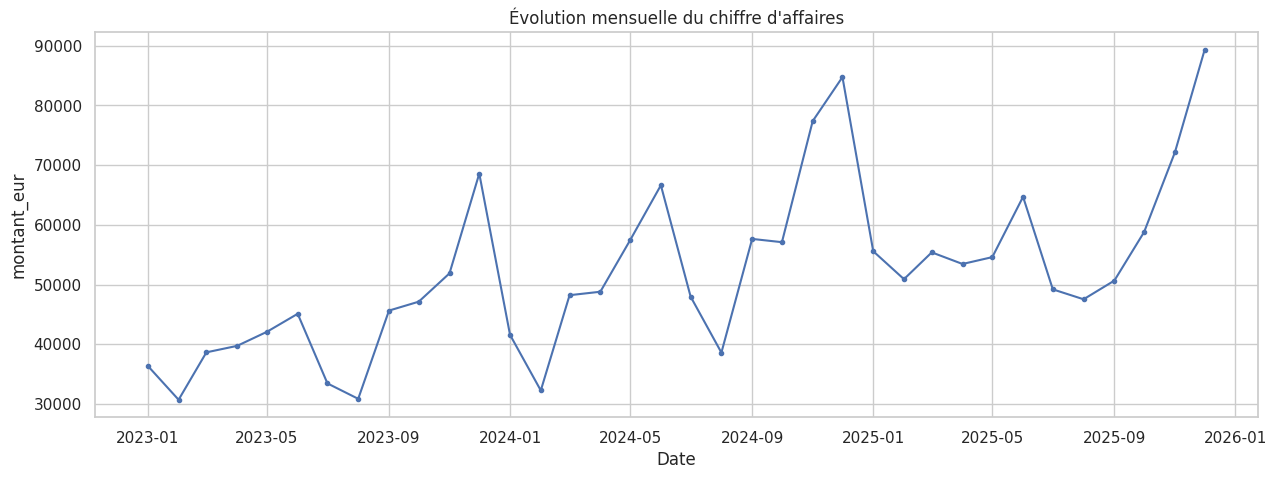

In [4]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
df = nettoyage_minimal(brut, cfg)
mensuel = df.set_index("date_commande").resample("MS").agg({cfg["ca"]: "sum"})

plt.figure(figsize=(15, 5))
plt.plot(mensuel.index, mensuel[cfg["ca"]], marker="o", markersize=3)
plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Date")
plt.ylabel(cfg["ca"])
plt.show()


Le graphique de l'évolution mensuelle du chiffre d'affaires de Maison Lumen (de 2023 à fin 2025) révèle plusieurs dynamiques clés :

Une tendance globale à la hausse (Croissance) :

Le chiffre d'affaires mensuel montre une trajectoire ascendante continue. Il débute sous la barre des 40 000 € au premier semestre 2023 et finit par frôler les 90 000 € en décembre 2025.
Une saisonnalité annuelle très marquée :

Les pics de fin d'année : On observe de grands pics annuels systématiques en novembre et décembre. C'est un comportement typique du commerce (achats de fin d'année et fêtes).
Un pic secondaire au printemps : On note également un rebond régulier de l'activité vers mai-juin.
Les creux saisonniers : Des baisses récurrentes de l'activité apparaissent chaque année en début d'année (janvier-février) ainsi qu'au milieu de l'été (juillet-août).
Un impact visible des changements opérationnels :

On constate une nette accélération et des planchers plus élevés à partir du milieu de l'année 2024. Cela coïncide parfaitement avec l'événement de la configuration, à savoir la refonte du site et le lancement de l'application mobile le 15 avril 2024, qui semble avoir donné un élan durable aux ventes

#

## 2. Les moyennes mobiles
Ajoutez une moyenne mobile sur 3 mois et une sur 12 mois. Que montre chacune ?

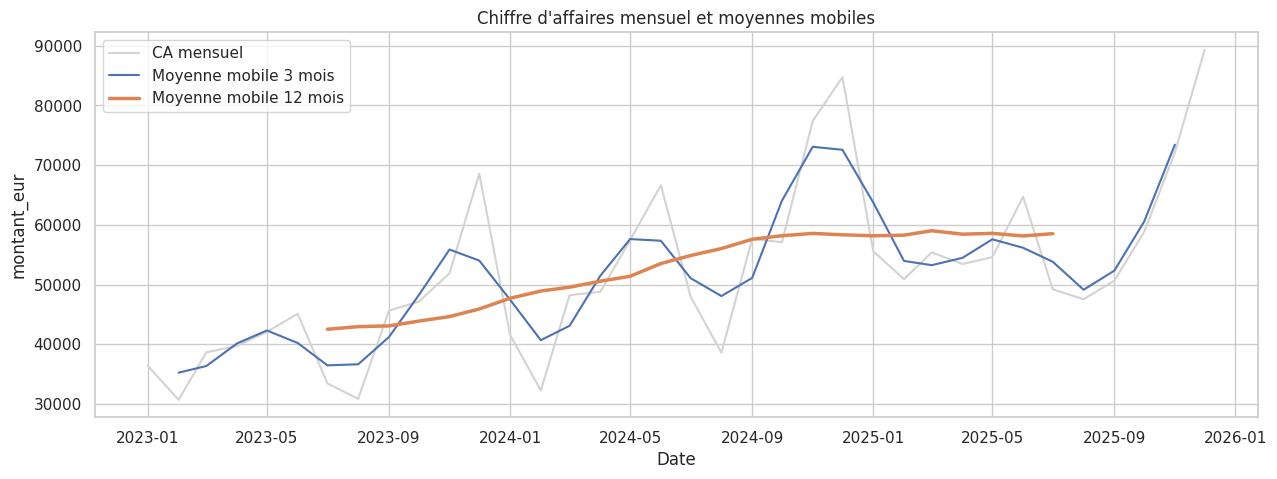

In [5]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
ca = mensuel[cfg["ca"]]
mm3 = ca.rolling(3, center=True).mean()
mm12 = ca.rolling(12, center=True).mean()

plt.figure(figsize=(15, 5))
plt.plot(ca, color="lightgray", label="CA mensuel")
plt.plot(mm3, label="Moyenne mobile 3 mois")
plt.plot(mm12, linewidth=2.5, label="Moyenne mobile 12 mois")
plt.title("Chiffre d'affaires mensuel et moyennes mobiles")
plt.xlabel("Date")
plt.ylabel(cfg["ca"])
plt.legend()
plt.savefig("moyennes_mobiles.png", bbox_inches="tight")  # avant plt.show(), sinon l'image est vide
plt.show()


 la moyenne mobile sur 3 mois lisse les variations d'un mois à l'autre mais conserve la saisonnalité (pics de fin d'année, creux d'été) ; elle décrit la conjoncture de court terme. La moyenne mobile sur 12 mois couvre un cycle complet : elle neutralise la saisonnalité et isole la tendance de fond, en hausse jusqu'à mi-2024 puis plus stable.

## 3. La décomposition saisonnière
Un événement exceptionnel fausse les coefficients saisonniers : remplacez d'abord les mois atypiques listés dans `cfg["atypiques"]` (les Jeux olympiques pour Les Escales) par la moyenne du même mois les autres années. Puis décomposez (`period=12`). Modèle additif ou multiplicatif : lequel convient, et pourquoi ?

Aucun mois atypique pour ce secteur


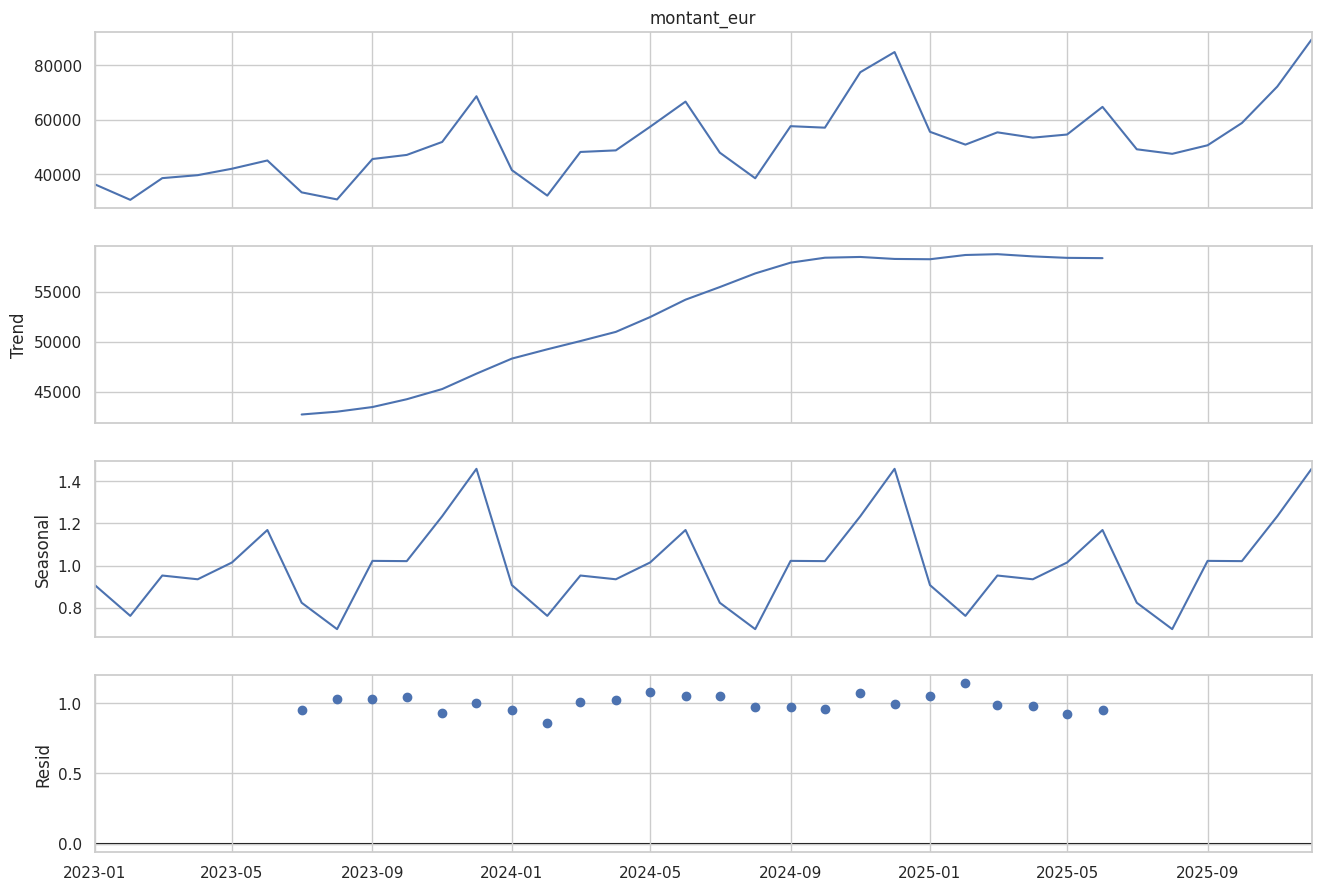

,coefficient saisonnier
date_commande,
1,0.907
2,0.761
3,0.953
4,0.935
5,1.015
6,1.169
7,0.824
8,0.698
9,1.022


In [6]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
from statsmodels.tsa.seasonal import seasonal_decompose

serie = mensuel[cfg["ca"]].copy()

# Remplacement des mois atypiques par la moyenne du même mois les autres années
atypiques = cfg.get("atypiques") or []
for d in atypiques:
    d = pd.Timestamp(d[0] if isinstance(d, (list, tuple)) else d).to_period("M").to_timestamp()
    if d in serie.index:
        meme_mois = serie[(serie.index.month == d.month) & (serie.index != d)]
        serie[d] = meme_mois.mean()
        print(f"{d:%Y-%m} remplacé par la moyenne des autres {d:%B} : {meme_mois.mean():,.0f}")
if not atypiques:
    print("Aucun mois atypique pour ce secteur")

# Modèle multiplicatif : l'amplitude saisonnière grandit avec le niveau
dec = seasonal_decompose(serie, model="multiplicative", period=12)

fig = dec.plot()
fig.set_size_inches(15, 10)
plt.show()

# Coefficients saisonniers (1 = mois "normal")
coef = dec.seasonal.groupby(dec.seasonal.index.month).first().round(3)
display(coef.rename("coefficient saisonnier"))


L'amplitude des pics saisonniers augmente avec le niveau de la série : le pic de décembre dépasse la tendance d'environ 22 k€ en 2023 et d'environ 26 k€ en 2024. Les variations saisonnières sont donc proportionnelles au niveau du CA, ce qui correspond à un modèle multiplicatif (série = tendance × saisonnalité × résidu). Les coefficients obtenus s'interprètent directement : un coefficient de 1,40 signifie un mois 40 % au-dessus de la normale.

> Ajouter une citation



## 4. La croissance sur un an
Calculez la croissance par rapport au même mois de l'année précédente (`pct_change(12)`) et tracez-la avec la date de l'événement du brief (`cfg["evenement"]`).

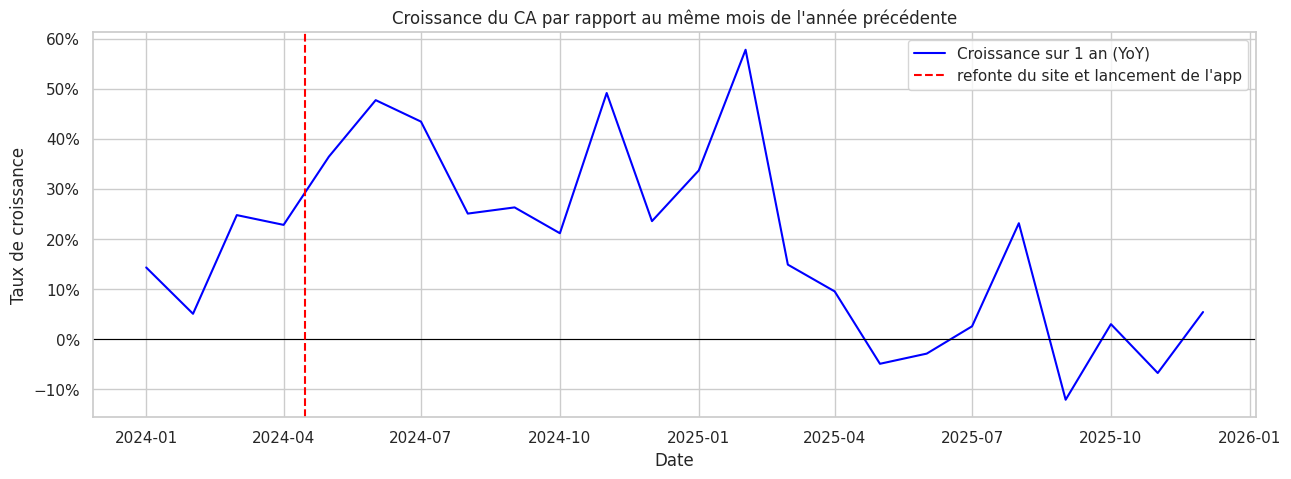

In [7]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
yoy = serie.pct_change(12)

date_evt_str, label_evt = cfg["evenement"]
date_evt = pd.to_datetime(date_evt_str)

plt.figure(figsize=(15, 5))
plt.plot(yoy, label="Croissance sur 1 an (YoY)", color="blue")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(date_evt, color="red", linestyle="--", label=label_evt)
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.title("Croissance du CA par rapport au même mois de l'année précédente")
plt.xlabel("Date")
plt.ylabel("Taux de croissance")
plt.legend()
plt.show()


la croissance sur un an passe d'environ +5 à +25 % avant l'événement à +37 à +48 % entre mai et juillet 2024, et reste élevée jusqu'en février 2025. À partir du printemps 2025, elle revient autour de 0 % : on compare désormais à des mois qui bénéficiaient déjà de l'effet de l'événement. Il s'agit donc d'un changement de niveau ponctuel, pas d'une accélération durable de la croissance.

## 5. Localiser la rupture sans connaître la date
Retirez la saisonnalité (série ÷ coefficient saisonnier), puis cherchez le mois où l'écart entre la moyenne des 6 mois suivants et celle des 6 mois précédents est le plus fort. Vérifiez avec un test de Student.

Rupture détectée en : March 2024
Écart de moyenne (6 mois après - 6 mois avant) : 10,317 €
Test de Student (Welch) : t = 6.98, p-value = 6.89e-05


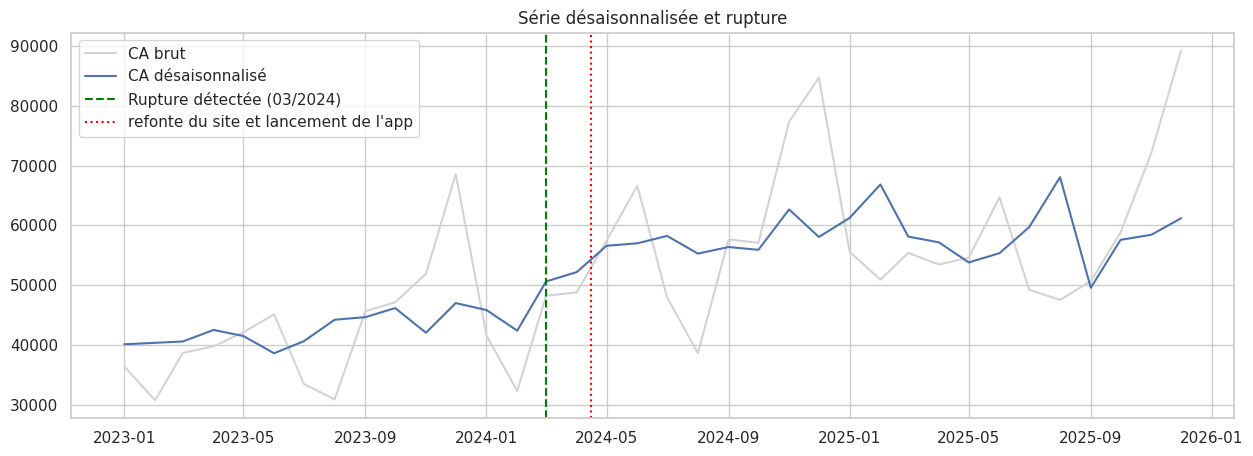

In [8]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
from scipy import stats

# Désaisonnalisation (cohérente avec le modèle multiplicatif)
desaison = serie / dec.seasonal

resultats = []
for i in range(6, len(desaison) - 5):          # 6 mois avant, 6 mois après (mois i inclus)
    avant = desaison.iloc[i-6:i]
    apres = desaison.iloc[i:i+6]
    t, p = stats.ttest_ind(apres, avant, equal_var=False)   # test de Welch
    resultats.append({"mois": desaison.index[i],
                      "ecart": apres.mean() - avant.mean(),
                      "t": t, "p_value": p})
resultats = pd.DataFrame(resultats).set_index("mois")

rupture = resultats["ecart"].abs().idxmax()
r = resultats.loc[rupture]
print(f"Rupture détectée en : {rupture:%B %Y}")
print(f"Écart de moyenne (6 mois après - 6 mois avant) : {r.ecart:,.0f} €")
print(f"Test de Student (Welch) : t = {r.t:.2f}, p-value = {r.p_value:.2e}")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(serie, color="lightgray", label="CA brut")
ax.plot(desaison, label="CA désaisonnalisé")
ax.axvline(rupture, color="green", linestyle="--", label=f"Rupture détectée ({rupture:%m/%Y})")
ax.axvline(date_evt, color="red", linestyle=":", label=label_evt)
ax.set_title("Série désaisonnalisée et rupture")
ax.legend()
plt.show()


**Votre lecture** : à compléter avec les chiffres affichés ci-dessus (mois détecté, écart en €, p-value). Si la p-value est inférieure à 0,05, on rejette l'hypothèse d'égalité des moyennes avant/après : la rupture est statistiquement significative. Comparer ensuite le mois détecté avec la date de l'événement (15 avril 2024) et expliquer un éventuel décalage (fenêtre de 6 mois, montée en charge progressive de l'application).

## 6. Expliquer la rupture
Qu'est-ce qui change autour de la rupture ? Comparez la part de chaque segment dans le chiffre d'affaires, par trimestre.

canal,app,magasin,web
trimestre,,,
2023Q1,5.9,62.7,31.5
2023Q2,4.1,65.7,30.2
2023Q3,3.8,60.6,35.6
2023Q4,4.6,62.0,33.5
2024Q1,4.4,62.4,33.2
2024Q2,13.1,44.3,42.7
2024Q3,17.4,40.3,42.3
2024Q4,14.3,42.2,43.5
2025Q1,18.8,43.2,38.1


canal,app,magasin,web
trimestre,,,
2023Q1,6217.0,66257.0,33262.0
2023Q2,5261.0,83361.0,38313.0
2023Q3,4219.0,66600.0,39136.0
2023Q4,7644.0,103856.0,56109.0
2024Q1,5344.0,76218.0,40501.0
2024Q2,22592.0,76545.0,73728.0
2024Q3,25072.0,58075.0,61079.0
2024Q4,31426.0,92480.0,95329.0
2025Q1,30368.0,69859.0,61661.0


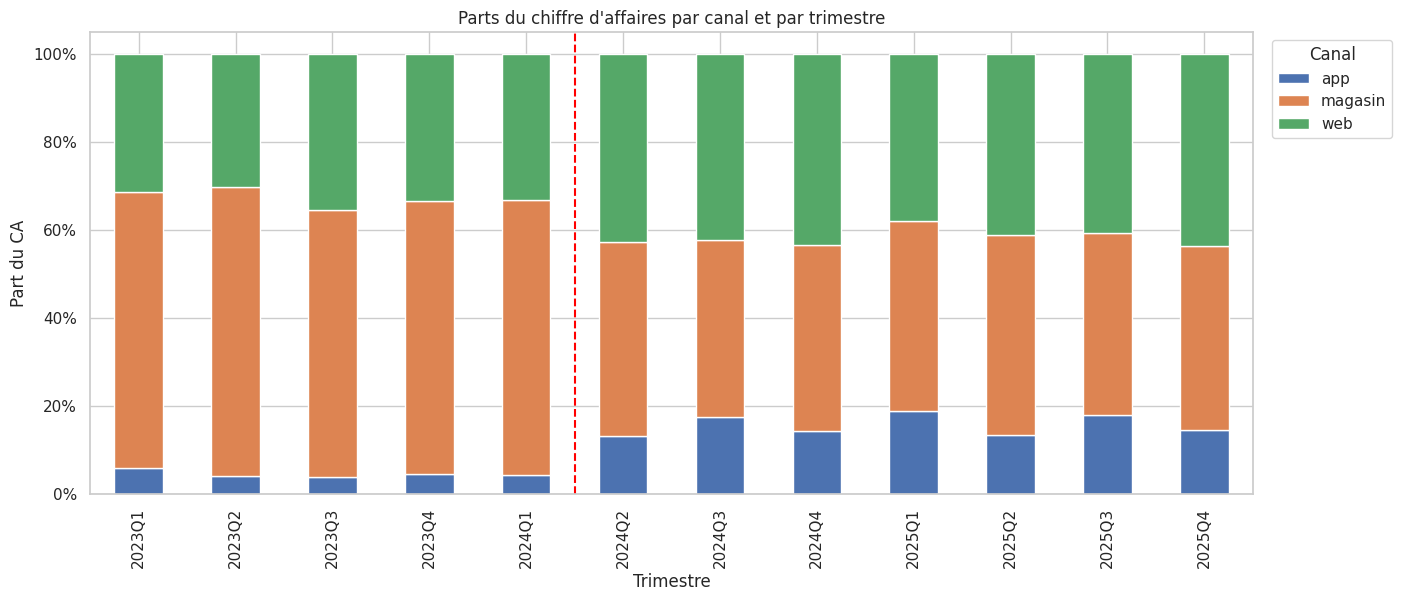

In [9]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
df["trimestre"] = df["date_commande"].dt.to_period("Q")

ca_par_segment = df.groupby(["trimestre", cfg["segment"]])[cfg["ca"]].sum().unstack()
parts = ca_par_segment.div(ca_par_segment.sum(axis=1), axis=0)

display((parts * 100).round(1))      # parts en %
display(ca_par_segment.round(0))     # montants en € : part qui baisse = CA qui baisse ?

ax = parts.plot(kind="bar", stacked=True, figsize=(15, 6))
ax.axvline(list(parts.index.astype(str)).index(str(date_evt.to_period("Q"))) - 0.5,
           color="red", linestyle="--")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.title("Parts du chiffre d'affaires par canal et par trimestre")
plt.ylabel("Part du CA")
plt.xlabel("Trimestre")
plt.legend(title="Canal", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()


In [10]:
import plotly.express as px

# Préparation des données plotly (conversion de l'index Period en chaîne de caractères)
parts_plotly = parts.copy()
parts_plotly.index = parts_plotly.index.astype(str)
parts_plotly = parts_plotly.reset_index()

# Transformation du format large au format long pour Plotly Express
parts_melted = parts_plotly.melt(id_vars='trimestre', var_name='Canal', value_name='Part de CA')

# Création du graphique à barres empilées interactif
fig = px.bar(
    parts_melted,
    x='trimestre',
    y='Part de CA',
    color='Canal',
    title="Évolution interactive des parts de chiffre d'affaires par canal",
    labels={'trimestre': 'Trimestre', 'Part de CA': 'Part du Chiffre d\'Affaires'},
    barmode='stack'
)

fig.update_layout(
    yaxis_tickformat='.1%',
    legend_title_text='Canal (Segment)',
    xaxis_tickangle=-45,
    template='plotly_white'
)

fig.show()

**Lecture** : la structure du CA change au T2 2024. La part de l'application passe d'environ 4-6 % à 13 % puis 14-19 % ; celle du web d'environ 30-33 % à 41-44 % ; celle du magasin recule d'environ 62-66 % à 40-45 %. La rupture s'explique par la montée des canaux numériques après la refonte du site et le lancement de l'app. Le tableau en euros permet de vérifier si le magasin perd du CA en valeur (cannibalisation) ou seulement en part.

## 7. Bonus · un indicateur de la banque
Pour Crédit Azur, le chiffre d'affaires dépend du **taux d'accord**. Tracez le taux d'accord mensuel : la rupture y est-elle plus nette ?

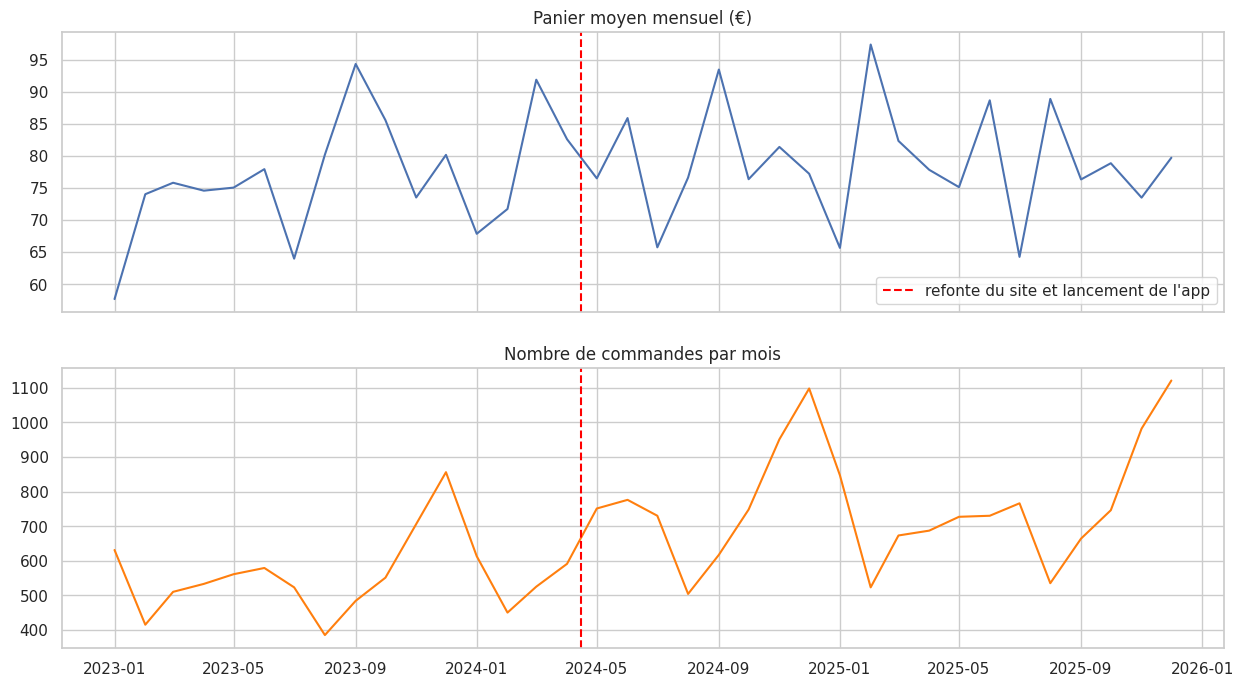

                avant    après  variation
panier_moyen   76.653   79.058      0.031
nb_commandes  557.062  758.800      0.362


In [11]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Le taux d'accord n'existe que pour la banque. Pour le commerce, on regarde
# le panier moyen et le nombre de commandes pour savoir d'où vient la hausse du CA.
par_mois = df.set_index("date_commande").resample("MS")[cfg["ca"]]
indic = pd.DataFrame({"panier_moyen": par_mois.mean(), "nb_commandes": par_mois.count()})

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
axes[0].plot(indic["panier_moyen"])
axes[0].set_title("Panier moyen mensuel (€)")
axes[1].plot(indic["nb_commandes"], color="tab:orange")
axes[1].set_title("Nombre de commandes par mois")
for ax in axes:
    ax.axvline(date_evt, color="red", linestyle="--", label=label_evt)
axes[0].legend()
plt.show()

avant, apres = indic[indic.index < date_evt], indic[indic.index >= date_evt]
print((pd.DataFrame({"avant": avant.mean(), "après": apres.mean()})
       .assign(variation=lambda x: x["après"] / x["avant"] - 1)).round(3))


**Vos conclusions** (3 phrases, chacune avec un chiffre) : à rédiger à partir des résultats, par exemple : (1) le niveau du CA désaisonnalisé augmente de X € par mois à partir de [mois de rupture], avec une p-value de Y ; (2) la part des canaux numériques passe d'environ 35 % à environ 57 % du CA ; (3) le panier moyen varie de Z %, donc la hausse vient surtout du nombre de commandes.

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Séries temporelles : saisonnalité et rupture »